# MD1 · Segmentación de clientes
### H&M Personalized Fashion Recommendations · Grupo 2 · Minería de Datos · Semana 12

**Modalidad:** `COMPLETA` · **Salida:** dos ZIP (evidencias y modelos) + notebook ejecutado.

**Objetivo:** recencia, frecuencia de registros y valor agregado de price. **Métodos:** K-means y K-medoids (PAM).

**Ruta de lectura:** planteamiento → entorno → datos → exploración → diseño → variables → modelado → evaluación visual → test → interpretación → persistencia → auditoría/ZIP → conclusiones.

> **Integridad:** las pruebas P01–P04 conservan sus criterios originales. Un proceso `OK` sin patrones no equivale a evidencia de minería. Las decisiones se toman antes de abrir el test; los modelos de despliegue se distinguen de los evaluados. Los `.joblib` y `.pkl` solo deben cargarse desde fuentes confiables.


## 1. Planteamiento y alcance

**Pregunta de investigación:** ¿Qué aporta K-means y K-medoids (PAM) para recencia, frecuencia de registros y valor agregado de price?  Los experimentos P01–P04 se ejecutan y se evalúan bajo las particiones y reglas del protocolo aprobado.


## 2. Entorno reproducible y configuración

**Modo `COMPLETA`:** instalación condicional, semilla, firma de entradas, cachés y trazabilidad. Las salidas se escriben en `/kaggle/working/hm_modelamiento`.


In [1]:
import importlib.util,subprocess,sys
DEPENDENCIAS = [('duckdb', 'duckdb==1.3.2'), ('kmedoids', 'kmedoids==0.5.5')]
missing=[pkg for module,pkg in DEPENDENCIAS if importlib.util.find_spec(module) is None]
if missing:
    print('Dependencias faltantes:', missing)
    try: subprocess.check_call([sys.executable,'-m','pip','install','--quiet',*missing])
    except Exception as exc:
        raise RuntimeError('No se pudieron instalar dependencias. En Kaggle habilita Internet en Notebook Options, o adjunta ruedas compatibles.') from exc
else:print('Dependencias específicas ya instaladas.')


Dependencias faltantes: ['kmedoids==0.5.5']


In [2]:
# Configuración portable: Kaggle primero, pero sin asumir rutas fijas.
from pathlib import Path
import os, json, time, platform, hashlib, warnings, sys
import numpy as np, pandas as pd
from packaging.version import Version
from importlib.metadata import version, PackageNotFoundError
import psutil
DATA_FILENAMES = {'transactions':'transacciones_preparadas.parquet',
                  'customers':'clientes_preparados.parquet',
                  'segmentation':'clientes_vista_segmentacion.parquet',
                  'articles':'articles_preparado.parquet'}
KAGGLE_CANDIDATE = Path('/kaggle/input/datasets/marcocastilla/hm-grupo2-datos-preparados')
INPUT_DIR = Path(os.environ.get('HM_INPUT_DIR', str(KAGGLE_CANDIDATE)))
if not all((INPUT_DIR / x).is_file() for x in DATA_FILENAMES.values()):
    roots=[Path('/kaggle/input'), Path.cwd(), Path('/mnt/data')]
    found=[]
    for root in roots:
        if root.is_dir():
            for path in root.rglob('transacciones_preparadas.parquet'):
                if all((path.parent / fn).is_file() for fn in DATA_FILENAMES.values()): found.append(path.parent.resolve())
    found=list(dict.fromkeys(found))
    if len(found)!=1: raise FileNotFoundError(f'Esperado un único directorio con los cuatro Parquet. Encontrados: {found}. Defina HM_INPUT_DIR.')
    INPUT_DIR=found[0]
FILES={k:INPUT_DIR / v for k,v in DATA_FILENAMES.items()}
OUTPUT_ROOT=Path(os.environ.get('HM_OUTPUT_DIR','/kaggle/working/hm_modelamiento' if Path('/kaggle/working').is_dir() else str(Path.cwd()/'hm_modelamiento')))
OUTPUT_ROOT.mkdir(parents=True,exist_ok=True)
print('Datos:',INPUT_DIR,'RAM disponible GiB:',round(psutil.virtual_memory().available/2**30,2))
print('CPU lógicas:',os.cpu_count(),'Python:',sys.version.split()[0])
print({k:(str(v), round(v.stat().st_size/2**20,1)) for k,v in FILES.items()})
def _has_pkg(n):
    try:version(n);return True
    except PackageNotFoundError:return False
try:
    import duckdb
except ImportError as exc:
    raise RuntimeError('Falta duckdb. En Kaggle: habilitar instalación si es necesaria y ejecutar %pip install duckdb==1.3.2') from exc
con=duckdb.connect(database=':memory:')
con.execute('PRAGMA threads=4')
con.execute("SET memory_limit='8GB'")
PTRANS=str(FILES['transactions']).replace("'", "''")
PART=str(FILES['articles']).replace("'", "''")
PCUST=str(FILES['customers']).replace("'", "''")
PSEG=str(FILES['segmentation']).replace("'", "''")

OUT=OUTPUT_ROOT/'md1';OUT.mkdir(parents=True,exist_ok=True)
def save_csv(df, filename):
    p=OUT/filename; p.parent.mkdir(parents=True,exist_ok=True)
    pd.DataFrame(df).to_csv(p,index=False); print('Guardado:',p); return p

def save_json(obj, filename):
    p=OUT/filename; p.parent.mkdir(parents=True,exist_ok=True)
    p.write_text(json.dumps(obj,ensure_ascii=False,indent=2,default=str),encoding='utf-8')
    print('Guardado:',p);return p

def sha256_path(path):
    h=hashlib.sha256()
    with open(path,'rb') as f:
        for b in iter(lambda:f.read(8*1024*1024),b''):h.update(b)
    return h.hexdigest()

SOURCE={'sha256':{k:sha256_path(v) for k,v in FILES.items()},'runtime':platform.platform(),'python':sys.version.split()[0],
        'packages':{n:(version(n) if _has_pkg(n) else None) for n in ['numpy','pandas','scikit-learn','statsmodels','duckdb']}}
save_json(SOURCE,'entrada_y_entorno.json')
STATUS=[]
def registro(prueba,etapa,estado,detalle='',duracion_s=None):
    item={'prueba':prueba,'etapa':etapa,'estado':estado,'detalle':str(detalle),'duracion_s':duracion_s}
    STATUS.append(item)
    pd.DataFrame(STATUS).to_csv(OUT/'estado_experimentos.csv',index=False)
    return item


Datos: /kaggle/input/datasets/marcocastilla/hm-grupo2-datos-preparados RAM disponible GiB: 30.0
CPU lógicas: 4 Python: 3.13.18
{'transactions': ('/kaggle/input/datasets/marcocastilla/hm-grupo2-datos-preparados/transacciones_preparadas.parquet', 448.3), 'customers': ('/kaggle/input/datasets/marcocastilla/hm-grupo2-datos-preparados/clientes_preparados.parquet', 160.2), 'segmentation': ('/kaggle/input/datasets/marcocastilla/hm-grupo2-datos-preparados/clientes_vista_segmentacion.parquet', 80.4), 'articles': ('/kaggle/input/datasets/marcocastilla/hm-grupo2-datos-preparados/articles_preparado.parquet', 16.9)}
Guardado: /kaggle/working/hm_modelamiento/md1/entrada_y_entorno.json


In [3]:

# Cache cannot be silently reused with a different set of input files.
INPUT_SIGNATURE = SOURCE['sha256']
p_input = OUT / 'origen_cache.json'
if p_input.exists():
    old = json.loads(p_input.read_text(encoding='utf-8'))
    if old.get('sha256') != INPUT_SIGNATURE:
        raise RuntimeError('El origen cambió respecto a los cachés previos. Usar un nuevo HM_OUTPUT_DIR o depurar cachés de forma controlada.')
else:
    p_input.write_text(json.dumps({'sha256':INPUT_SIGNATURE},indent=2),encoding='utf-8')


In [4]:
# Monitor auxiliar, transversal y no intrusivo (no altera las estimaciones).
import threading, time as _hm_time, psutil as _hm_psutil
_HM_MONITOR=None
def hm_monitor_inicio(etapa, cada=30):
    global _HM_MONITOR
    hm_monitor_fin()
    e=threading.Event(); t0=_hm_time.monotonic(); proc=_hm_psutil.Process()
    def loop():
        while not e.wait(cada):
            try:
                print(f'[PROGRESO] {etapa} | {_hm_time.monotonic()-t0:.0f} s | RAM proceso {proc.memory_info().rss/2**30:.2f} GiB', flush=True)
            except Exception: return
    t=threading.Thread(target=loop,daemon=True); t.start();_HM_MONITOR=(e,t,t0,etapa)
    print(f'[INICIO] {etapa}',flush=True)
def hm_monitor_fin():
    global _HM_MONITOR
    if _HM_MONITOR is not None:
        ev,t,t0,label=_HM_MONITOR; ev.set();t.join(timeout=1)
        print(f'[FIN] {label}: {_hm_time.monotonic()-t0:.1f} s',flush=True)
        _HM_MONITOR=None


## 3. Carga y validación de datos

Validar las fuentes reales. No sustituir errores de entrada por muestras sintéticas.


In [5]:
RFM_FILE=OUT/'rfm_hm.parquet'
if not RFM_FILE.exists():
    con.execute(f"""COPY (
      SELECT customer_id, DATE_DIFF('day',MAX(t_dat::DATE),DATE '2020-09-23')::INTEGER AS recencia_dias,
      COUNT(*)::BIGINT AS frecuencia_registros,
      SUM(price)::DOUBLE AS valor_agregado_price
      FROM read_parquet('{PTRANS}') GROUP BY 1
    ) TO '{str(RFM_FILE).replace(chr(39),chr(39)*2)}' (FORMAT PARQUET)""")
rfm=con.execute(f"SELECT * FROM read_parquet('{str(RFM_FILE)}') ORDER BY customer_id").df()
assert len(rfm)==rfm.customer_id.nunique()==1_362_281
assert (rfm.recencia_dias>=1).all() and (rfm.frecuencia_registros>=1).all()
assert (rfm.valor_agregado_price>=0).all() and np.isfinite(rfm.valor_agregado_price).all()
assert int(rfm.frecuencia_registros.sum())==31_788_324
original_sum=con.execute(f"SELECT SUM(price) FROM read_parquet('{PTRANS}')").fetchone()[0]
assert np.isclose(original_sum,rfm.valor_agregado_price.sum(),rtol=1e-9,atol=1e-6)
assert int(con.execute(f"SELECT COUNT(*) FROM read_parquet('{PCUST}')").fetchone()[0])-len(rfm)==9699
registro('MD1-P01','validar_RFM','PASS',len(rfm))
print('RFM conciliado:',len(rfm),'F:',rfm.frecuencia_registros.sum(),'M:',rfm.valor_agregado_price.sum())


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

RFM conciliado: 1362281 F: 31788324 M: 884645.9740508472


## 4. Exploración orientada al modelado

**Lectura:** examina distribuciones y cobertura antes de ajustar, sin imprimir identificadores individuales.


**Distribuciones RFM (percentiles agregados)**

,recencia_dias,frecuencia_registros,valor_agregado_price
count,1362281.000,1362281.000,1362281.000
mean,236.148,23.335,0.649
std,221.119,39.242,1.198
min,1.000,1.000,0.001
25%,49.000,3.000,0.088
50%,152.000,9.000,0.246
75%,399.000,27.000,0.701
90%,609.000,60.000,1.623
99%,725.000,187.000,5.699
max,734.000,1895.000,57.676


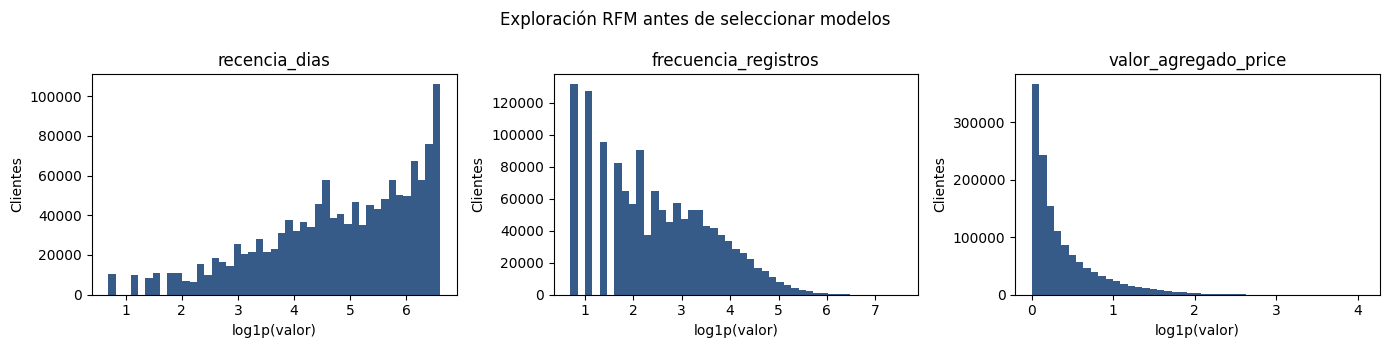

In [6]:
# Exploración pequeña de la vista RFM; no exporta identificadores.
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
cols=['recencia_dias','frecuencia_registros','valor_agregado_price']
display(Markdown('**Distribuciones RFM (percentiles agregados)**'))
display(rfm[cols].describe(percentiles=[.25,.5,.75,.9,.99]).round(3))
fig,ax=plt.subplots(1,3,figsize=(14,3.5))
for a,k in zip(ax,cols):
    x=np.log1p(np.maximum(rfm[k].to_numpy(dtype=float),0))
    a.hist(x,bins=45,color='#365b88');a.set(title=k,xlabel='log1p(valor)',ylabel='Clientes')
fig.suptitle('Exploración RFM antes de seleccionar modelos');fig.tight_layout()
fig.savefig(OUT/'md1_exploracion_rfm.png',dpi=135);plt.show();plt.close(fig)


## 5. Diseño experimental y criterios de evaluación

**Métodos:** K-means y K-medoids (PAM). **Pruebas:** MD1-P01 a MD1-P04. La selección se decide con desarrollo/validación; test solo evalúa. Los estados incompletos se reportan, nunca se sustituyen por métricas ficticias.


## 6. Preparación de variables, matrices y particiones

Transformaciones reproducibles y particiones congeladas antes de evaluación retenida.


In [7]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import silhouette_samples,silhouette_score,adjusted_rand_score,pairwise_distances
from sklearn.cluster import KMeans
from sklearn.preprocessing import RobustScaler
import itertools, multiprocessing as mp, queue
BASE_SEED=20261011
seedseq=np.random.SeedSequence(BASE_SEED); seeds=[int(s.generate_state(1)[0]) for s in seedseq.spawn(80)]
hashkey=pd.util.hash_pandas_object(rfm.customer_id,index=False).to_numpy(dtype='uint64')
rfm['estrato']=0
idx=np.flatnonzero(rfm.frecuencia_registros.to_numpy()>1)
# Orden F y hash: el desempate entre frecuencias idénticas no es aleatorio de cada ejecución.
arr=rfm.frecuencia_registros.to_numpy()
ordered=idx[np.lexsort((hashkey[idx],arr[idx]))]
rank=np.arange(len(ordered)) / max(1,len(ordered))
rfm.loc[ordered,'estrato']=np.select([rank<.5,rank<.9,rank<.99],[1,2,3],default=4)
all_indices=np.arange(len(rfm))
adjust,other=train_test_split(all_indices,train_size=.8,random_state=seeds[0],stratify=rfm.estrato)
select,final=train_test_split(other,train_size=.5,random_state=seeds[1],stratify=rfm.estrato.iloc[other])
assert not(set(adjust)&set(select) or set(adjust)&set(final) or set(select)&set(final))

def strat_sample(pool,n,seed):
    pool=np.asarray(pool);groups=rfm.estrato.iloc[pool].to_numpy();rng=np.random.default_rng(seed)
    if n>=len(pool):return np.sort(pool)
    uniq,counts=np.unique(groups,return_counts=True)
    quotas=np.minimum(counts,np.maximum(np.minimum(10,counts),np.floor(n*counts/len(pool)).astype(int)))
    while quotas.sum()<n:
        candidates=np.flatnonzero(quotas<counts)
        if not len(candidates):break
        ix=candidates[np.argmax((n*counts/len(pool)-quotas)[candidates])];quotas[ix]+=1
    while quotas.sum()>n:
        candidates=np.flatnonzero(quotas>np.minimum(10,counts))
        if not len(candidates):raise ValueError('Muestra demasiado pequeña para mínimos por estrato')
        ix=candidates[np.argmax(quotas[candidates]-n*counts[candidates]/len(pool))];quotas[ix]-=1
    chosen=[]
    for group,num in zip(uniq,quotas):
        sub=pool[groups==group]
        # Prioridad aleatoria estable por estrato; anidamiento usando el mismo seed.
        chosen.extend(rng.permutation(sub)[:int(num)])
    return np.sort(np.asarray(chosen,dtype=int))
# Congelar referencias antes de mirar etiquetas, usando semillas distintas.
sel_ref=strat_sample(select,2000,seeds[3]);test_ref=strat_sample(final,2000,seeds[4])
base_pool=strat_sample(adjust,4000,seeds[2])
# Estratos y muestras anidadas: se toma un orden estable y sus prefijos; los tamaños se validan.
# Orden estratificado por cuotas, ANIDADO y con al menos 10 por estrato
# en todos los tamaños piloto. Un prefijo es subconjunto exacto del siguiente.
rng_base=np.random.default_rng(seeds[2])
by_group={g:list(rng_base.permutation(base_pool[rfm.estrato.iloc[base_pool].to_numpy()==g]))
          for g in sorted(rfm.estrato.iloc[base_pool].unique())}
groups=list(by_group);counts={g:len(by_group[g]) for g in groups}
used={g:0 for g in groups};base_sequence=[]
for g in groups:
    take=min(10,counts[g]);base_sequence.extend(by_group[g][:take]);used[g]=take
while len(base_sequence)<len(base_pool):
    available=[g for g in groups if used[g]<counts[g]]
    target=len(base_sequence)+1
    g=max(available,key=lambda j:target*counts[j]/len(base_pool)-used[j])
    base_sequence.append(by_group[g][used[g]]);used[g]+=1
base_order=np.asarray(base_sequence,dtype=int)
base_sizes={n:np.sort(base_order[:n]) for n in (500,1000,2000,4000)}
assert all(set(base_sizes[a]).issubset(set(base_sizes[b])) for a,b in [(500,1000),(1000,2000),(2000,4000)])
for n,z in base_sizes.items():assert len(z)==n
pd.DataFrame({'idx':sel_ref,'customer_id':rfm.customer_id.iloc[sel_ref]}).to_csv(OUT/'referencia_seleccion.csv',index=False)
pd.DataFrame({'idx':test_ref,'customer_id':rfm.customer_id.iloc[test_ref]}).to_csv(OUT/'referencia_test.csv',index=False)
print('Partición:',len(adjust),len(select),len(final),'Referencia:',len(sel_ref),len(test_ref))


Partición: 1089824 136228 136229 Referencia: 2000 2000


## 7. Modelamiento y selección

Se ejecuta el protocolo completo, con guardado progresivo. Las técnicas no admiten resultados inventados en caso de timeout.


In [8]:
try:
    import kmedoids
except ImportError as exc:
    raise RuntimeError('Falta paquete kmedoids. Instalar kmedoids en Kaggle antes de ejecutar MD1.') from exc

def prepare_fit(indices,kind='main'):
    v=rfm.iloc[indices][['recencia_dias','frecuencia_registros','valor_agregado_price']].to_numpy(dtype=float)
    if kind=='rf':v=v[:,:2]
    if kind=='cap99':
        v[:,1:]=np.minimum(v[:,1:],np.quantile(v[:,1:],.99,axis=0))
    log=(kind!='raw')
    if log:v[:,1:]=np.log1p(v[:,1:])
    med=np.median(v,axis=0);iqr=np.percentile(v,75,axis=0)-np.percentile(v,25,axis=0)
    alt=np.percentile(v,95,axis=0)-np.percentile(v,5,axis=0)
    scale=np.where(iqr>0,iqr,alt)
    if np.any(scale<=0):raise ValueError('Variable con escala nula; configuración no evaluable')
    return (v-med)/scale,{'median':med,'scale':scale,'kind':kind,'cap':np.quantile(rfm.iloc[indices][['frecuencia_registros','valor_agregado_price']],.99,axis=0) if kind=='cap99' else None}
def trans(indices,state):
    v=rfm.iloc[indices][['recencia_dias','frecuencia_registros','valor_agregado_price']].to_numpy(dtype=float)
    if state['kind']=='rf':v=v[:,:2]
    if state['kind']=='cap99':v[:,1:]=np.minimum(v[:,1:],state['cap'])
    if state['kind']!='raw':v[:,1:]=np.log1p(v[:,1:])
    return (v-state['median'])/state['scale']

def _pam_worker(D,k,seed,q):
    t=time.monotonic()
    try:
        r=kmedoids.pam(D,k,init='random',random_state=int(seed),max_iter=300)
        q.put({'estado':'OK','medoids':list(map(int,r.medoids)),
               'loss':float(r.loss),'n_iter':int(getattr(r,'n_iter',-1)),
               'segundos':time.monotonic()-t})
    except Exception as exc:q.put({'estado':'ERROR','error':str(exc),'segundos':time.monotonic()-t})

def pam_safe(D,k,seed,limit=300):
    ctx=mp.get_context('fork');q=ctx.Queue();p=ctx.Process(target=_pam_worker,args=(D,k,seed,q))
    before=psutil.virtual_memory().available;start=time.monotonic();p.start();rss=0;reason=None
    while p.is_alive():
        try:rss=max(rss,psutil.Process(p.pid).memory_info().rss)
        except psutil.NoSuchProcess:break
        if rss>0.6*before:reason='MEMORIA';break
        if time.monotonic()-start>limit:reason='TIMEOUT';break
        p.join(.2)
    if p.is_alive():p.terminate();p.join(3)
    try:res=q.get(timeout=1) if reason is None else {'estado':reason}
    except queue.Empty:res={'estado':'ERROR','error':'Sin respuesta del proceso'}
    res.update({'incremento_rss_max_bytes':rss,'wall_s':time.monotonic()-start})
    return res

PILOTO=[];N_COMMON=None
for n,indices in base_sizes.items():
    XX,pr=prepare_fit(indices);D=pairwise_distances(XX,metric='euclidean').astype('float64')
    ok=True
    for k in (2,8):
        print(f'[PAM PILOTO] Inicio n={n} k={k}',flush=True)
        rr=pam_safe(D,k,seeds[5]+k,300)
        PILOTO.append({'n':n,'k':k,**{a:b for a,b in rr.items() if a!='medoids'}})
        # Checkpoint inmediato: si Kaggle interrumpe el kernel, queda la evidencia.
        save_csv(PILOTO,'md1_piloto_pam.csv')
        print(f"[PAM PILOTO] n={n} k={k} estado={rr['estado']} segundos={rr['wall_s']:.1f}",flush=True)
        if rr['estado']!='OK' or rr['wall_s']>300:
            ok=False
            break
    if ok:
        slowest=max(p['wall_s'] for p in PILOTO if p['n']==n)
        if 85*slowest<=120*60:N_COMMON=n
        else:ok=False
    if not ok:break
save_csv(PILOTO,'md1_piloto_pam.csv')
print('Muestra común factible=',N_COMMON)
registro('MD1-P01','piloto','PASS' if N_COMMON else 'INCONCLUSO',N_COMMON)


[PAM PILOTO] Inicio n=500 k=2
Guardado: /kaggle/working/hm_modelamiento/md1/md1_piloto_pam.csv
[PAM PILOTO] n=500 k=2 estado=OK segundos=0.1
[PAM PILOTO] Inicio n=500 k=8
Guardado: /kaggle/working/hm_modelamiento/md1/md1_piloto_pam.csv
[PAM PILOTO] n=500 k=8 estado=OK segundos=0.3
[PAM PILOTO] Inicio n=1000 k=2
Guardado: /kaggle/working/hm_modelamiento/md1/md1_piloto_pam.csv
[PAM PILOTO] n=1000 k=2 estado=OK segundos=0.2
[PAM PILOTO] Inicio n=1000 k=8
Guardado: /kaggle/working/hm_modelamiento/md1/md1_piloto_pam.csv
[PAM PILOTO] n=1000 k=8 estado=OK segundos=1.0
[PAM PILOTO] Inicio n=2000 k=2
Guardado: /kaggle/working/hm_modelamiento/md1/md1_piloto_pam.csv
[PAM PILOTO] n=2000 k=2 estado=OK segundos=0.4
[PAM PILOTO] Inicio n=2000 k=8
Guardado: /kaggle/working/hm_modelamiento/md1/md1_piloto_pam.csv
[PAM PILOTO] n=2000 k=8 estado=OK segundos=3.9
[PAM PILOTO] Inicio n=4000 k=2
Guardado: /kaggle/working/hm_modelamiento/md1/md1_piloto_pam.csv
[PAM PILOTO] n=4000 k=2 estado=OK segundos=4.0
[PA

{'prueba': 'MD1-P01',
 'etapa': 'piloto',
 'estado': 'PASS',
 'detalle': '4000',
 'duracion_s': None}

In [9]:
print('[MD1] Iniciando barrido completo k=2..8; el piloto PAM se ejecuta por proceso aislado.',flush=True)

[MD1] Iniciando barrido completo k=2..8; el piloto PAM se ejecuta por proceso aislado.


In [10]:
RUN_COMPLETE=N_COMMON is not None
FIT_BASE=base_sizes[N_COMMON] if RUN_COMPLETE else np.array([],dtype=int)
MAIN={} ; RESULTS=[]; STAB=[]; ALL_LABELS={}

def fit_model(kind,k,indices,seed,representation='main',D=None,X=None,state=None):
    if X is None:X,state=prepare_fit(indices,representation)
    if kind=='KMeans':
        estimator=KMeans(n_clusters=k,init='k-means++',n_init=1,algorithm='lloyd',tol=1e-4,max_iter=300,random_state=int(seed))
        estimator.fit(X)
        return {'kind':kind,'centers':estimator.cluster_centers_, 'obj':estimator.inertia_,
                'iter':int(estimator.n_iter_),'state':state,'n':k,'valid':estimator.n_iter_<300 and len(np.unique(estimator.labels_))==k}
    if D is None:D=pairwise_distances(X).astype('float64')
    res=pam_safe(D,k,seed)
    if res['estado']!='OK':return {'kind':kind,'valid':False,'error':res['estado']}
    meds=np.asarray(res['medoids'],dtype=int)
    return {'kind':kind,'centers':X[meds], 'medoid_rows':indices[meds],
            'obj':res['loss'],'iter':res['n_iter'],'state':state,'n':k,
            'valid':res['n_iter']<300 and len(np.unique(np.argmin(D[:,meds],axis=1)))==k}

def labels_of(model,indices):
    x=trans(indices,model['state']);return np.argmin(pairwise_distances(x,model['centers']),axis=1)

def stability(labels):
    ari=[adjusted_rand_score(labels[i],labels[j]) for i,j in itertools.combinations(range(5),2)]
    return np.median(ari),np.percentile(ari,75)-np.percentile(ari,25),ari

if RUN_COMPLETE:
    X,st=prepare_fit(FIT_BASE)
    D=pairwise_distances(X).astype('float64')
    remaps=[strat_sample(adjust,N_COMMON,seeds[20+i]) for i in range(5)]
    for k in range(2,9):
        for kind in ('KMeans','PAM'):
            models=[]
            for ix in range(5):
                model=fit_model(kind,k,FIT_BASE,seeds[30+ix],D=D,X=X,state=st)
                models.append(model)
            if not all(m['valid'] for m in models):
                registro('MD1-P02',f'{kind}_k{k}','INCOMPLETO','Inicialización fallida');continue
            models=sorted(models,key=lambda z:z['obj'])
            center=models[0];main_labels=[labels_of(m,sel_ref) for m in models]
            med_ari,iqr_ari,aris=stability(main_labels)
            resampled=[]
            for j,idx in enumerate(remaps):
                x2,st2=prepare_fit(idx);d2=pairwise_distances(x2).astype('float64') if kind=='PAM' else None
                m=fit_model(kind,k,idx,seeds[50],X=x2,state=st2,D=d2)
                if not m['valid']:break
                resampled.append(m)
            if len(resampled)!=5:
                registro('MD1-P02',f'{kind}_k{k}','INCOMPLETO','Remuestreo fallido');continue
            other_labels=[labels_of(m,sel_ref) for m in resampled]
            med_res,iqr_res,aris_res=stability(other_labels)
            labels=labels_of(center,sel_ref)
            pop=np.bincount(labels,minlength=k)
            minsize=max(10,int(np.ceil(.01*len(sel_ref))))
            eligible=bool(np.all(pop>=minsize) and len(pop)==k)
            sil=float(silhouette_score(trans(sel_ref,st),labels)) if eligible else np.nan
            MAIN[(kind,k)]={'model':center,'repetitions':models,'resamples':resampled,'labels':labels,
                'med_init':med_ari,'med_res':med_res,'sil':sil,'eligible':eligible}
            RESULTS.append({'modelo':kind,'k':k,'sil':sil,'ari_init':med_ari,'ari_resample':med_res,'eligible':eligible,
              'min_grupo':int(pop.min())})
            for block,values in [('init',aris),('resample',aris_res)]:
                for v in values:STAB.append({'modelo':kind,'k':k,'bloque':block,'ari':float(v)})
    save_csv(RESULTS,'md1_seleccion_k.csv');save_csv(STAB,'md1_ari_repeticiones.csv')
    krows=[]
    for k in range(2,9):
        if all((m,k) in MAIN and MAIN[(m,k)]['eligible'] for m in ('PAM','KMeans')):
            km,pm=MAIN[('KMeans',k)],MAIN[('PAM',k)]
            krows.append({'k':k,'silueta_media':(km['sil']+pm['sil'])/2,
             'min_ari':min(km['med_init'],pm['med_init'],km['med_res'],pm['med_res'])})
    if krows:
        mx=max(x['silueta_media'] for x in krows)
        K_CHOSEN=sorted([x for x in krows if mx-x['silueta_media']<=.02],key=lambda a:(-a['min_ari'],a['k']))[0]['k']
        save_json({'k':K_CHOSEN,'criterio':'Silueta <= .02 del max; max(min ARI); min k'},'md1_k_congelado.json')
        registro('MD1-P02','seleccion_k','PASS',K_CHOSEN)
    else:
        K_CHOSEN=None;registro('MD1-P02','seleccion_k','INCONCLUSO','Ningún k satisface cobertura y estabilidad')
else:K_CHOSEN=None


Guardado: /kaggle/working/hm_modelamiento/md1/md1_seleccion_k.csv
Guardado: /kaggle/working/hm_modelamiento/md1/md1_ari_repeticiones.csv
Guardado: /kaggle/working/hm_modelamiento/md1/md1_k_congelado.json


In [11]:
print('[MD1] Barrido de k y estabilidad terminado.',flush=True)

[MD1] Barrido de k y estabilidad terminado.


In [12]:
print('[MD1] Iniciando sensibilidad y evaluación retenida.',flush=True)

[MD1] Iniciando sensibilidad y evaluación retenida.


In [13]:
SENS=[];PERFILES=[];FINAL=[]
if K_CHOSEN is not None:
    for variant in ('raw','cap99','rf'):
        ix=FIT_BASE;xx,ss=prepare_fit(ix,variant)
        dd=pairwise_distances(xx).astype('float64')
        for kind in ('KMeans','PAM'):
            fitted=[fit_model(kind,K_CHOSEN,ix,seeds[30+j],representation=variant,D=dd,X=xx,state=ss) for j in range(5)]
            if not all(m['valid'] for m in fitted):
                registro('MD1-P03',kind+'_'+variant,'INCOMPLETO','Falló una de las cinco inicializaciones');continue
            rep_labels=[labels_of(m,sel_ref) for m in fitted]
            aris=[float(adjusted_rand_score(a,b)) for a,b in itertools.combinations(rep_labels,2)]
            best=min(fitted,key=lambda m:m['obj'])
            lbl=labels_of(best,sel_ref)
            base=MAIN[(kind,K_CHOSEN)]['labels']
            own=float(silhouette_score(trans(sel_ref,ss),lbl))
            rfm_sil=float(silhouette_score(trans(sel_ref,MAIN[(kind,K_CHOSEN)]['model']['state']),lbl))
            SENS.append({'modelo':kind,'variante':variant,'n_reinicios':len(fitted),
                'ari_mediana_entre_inicios':float(np.median(aris)),
                'ari_iqr_entre_inicios':float(np.percentile(aris,75)-np.percentile(aris,25)),
                'ari_vs_principal':float(adjusted_rand_score(base,lbl)),
                'silueta_propia':own,'silueta_rfm_principal':rfm_sil,
                'n_grupos_efectivos':len(np.unique(lbl))})
    save_csv(SENS,'md1_sensibilidad.csv')
    registro('MD1-P03','sensibilidad','PASS' if len(SENS)==6 else 'INCOMPLETO',f'{len(SENS)}/6 alternativas y cinco semillas')
    for kind in ('KMeans','PAM'):
        entry=MAIN[(kind,K_CHOSEN)];l=labels_of(entry['model'],test_ref)
        pop=np.bincount(l,minlength=K_CHOSEN)
        if (pop<max(10,int(np.ceil(.01*len(test_ref))))).any():
            registro('MD1-P04',kind,'INCOMPLETO','Tamaño de grupo mínimo en test');continue
        scaled=trans(test_ref,entry['model']['state'])
        sil=silhouette_samples(scaled,l)
        # Estabilidad final con referencia fija de test; k y representantes congelados.
        labels_init=[labels_of(m,test_ref) for m in entry['repetitions']]
        labels_res=[labels_of(m,test_ref) for m in entry['resamples']]
        ari_init=stability(labels_init)[0]; ari_res=stability(labels_res)[0]
        for g in range(K_CHOSEN):
            row={'modelo':kind,'k':K_CHOSEN,'grupo':g,'n':int(pop[g]),'proporcion':float(pop[g]/len(l)),
                'silueta':float(sil[l==g].mean()),'siluetas_negativas':int(np.sum(sil[l==g]<0))}
            sub=rfm.iloc[test_ref[l==g]]
            for name in ('recencia_dias','frecuencia_registros','valor_agregado_price'):
                row[name+'_mediana']=float(sub[name].median())
                row[name+'_iqr']=float(sub[name].quantile(.75)-sub[name].quantile(.25))
            PERFILES.append(row)
        FINAL.append({'modelo':kind,'k':K_CHOSEN,'silueta':float(sil.mean()),
            'ari_init_test':float(ari_init),'ari_remuestreo_test':float(ari_res),
            'n_test_referencia':len(test_ref),'muestra_ajuste':len(FIT_BASE)})
    save_csv(PERFILES,'md1_perfiles_finales.csv');save_csv(FINAL,'md1_evaluacion_final.csv')
    registro('MD1-P04','perfiles','PASS' if len(FINAL)==2 else 'INCOMPLETO',len(FINAL))
else:
    registro('MD1-P03','sensibilidad','PENDIENTE','Sin k congelado')

Guardado: /kaggle/working/hm_modelamiento/md1/md1_sensibilidad.csv
Guardado: /kaggle/working/hm_modelamiento/md1/md1_perfiles_finales.csv
Guardado: /kaggle/working/hm_modelamiento/md1/md1_evaluacion_final.csv


In [14]:
# Firmas de perfiles y representantes, exclusivamente después de congelar k.
FIRMAS=[];REPRESENTANTES=[];UNIQUE_COVERAGE={}
if len(FINAL)==2:
    vars_rfm=['recencia_dias','frecuencia_registros','valor_agregado_price']
    ref_quart=rfm.iloc[FIT_BASE][vars_rfm].quantile([.25,.75])
    for kind in ('KMeans','PAM'):
        # CRÍTICO: el test retenido NO interviene en la elección de algoritmo.
        # Las firmas usadas para decidir se obtienen únicamente de los clientes de SELECCIÓN.
        labels_sel=MAIN[(kind,K_CHOSEN)]['labels']
        for gi in range(K_CHOSEN):
            mask_sel=(labels_sel==gi)
            cluster_sel=rfm.iloc[sel_ref[mask_sel]]
            cats=[]
            for col in vars_rfm:
                value=float(cluster_sel[col].median())
                cats.append('B' if value<ref_quart.loc[.25,col] else ('A' if value>ref_quart.loc[.75,col] else 'M'))
            FIRMAS.append({'modelo':kind,'grupo':gi,'firma':'-'.join(cats),
                           'n':len(cluster_sel),'origen_firmas':'SELECCION_NO_TEST'})
        reps=MAIN[(kind,K_CHOSEN)]['model']
        if kind=='PAM':rep_rows=np.asarray(reps['medoid_rows'],dtype=int)
        else:
            XX=trans(FIT_BASE,reps['state'])
            assign=np.argmin(pairwise_distances(XX,reps['centers']),axis=1)
            rr=[]
            for g in range(K_CHOSEN):
                mask=np.flatnonzero(assign==g)
                if not len(mask):continue
                dist=np.sum((XX[mask]-reps['centers'][g])**2,axis=1)
                rr.append(int(FIT_BASE[mask[np.argmin(dist)]]))
            rep_rows=np.asarray(rr,dtype=int)
        for gi,idx in enumerate(rep_rows):
            obs=rfm.iloc[idx]
            REPRESENTANTES.append({'modelo':kind,'grupo':gi,
              'recencia_dias':int(obs.recencia_dias),'frecuencia_registros':int(obs.frecuencia_registros),
              'valor_agregado_price':float(obs.valor_agregado_price)})
        signatures=[f for f in FIRMAS if f['modelo']==kind]
        occurrences={x['firma']:sum(y['firma']==x['firma'] for y in signatures) for x in signatures}
        UNIQUE_COVERAGE[kind]=sum(x['n'] for x in signatures if occurrences[x['firma']]==1)/len(sel_ref)
    save_csv(FIRMAS,'md1_firmas.csv');save_csv(REPRESENTANTES,'md1_representantes_anonimos.csv')
    km=MAIN[('KMeans',K_CHOSEN)];pa=MAIN[('PAM',K_CHOSEN)]
    sil_pass=pa['sil']>=km['sil']-.02
    ari_pass=(pa['med_init']>=km['med_init']-.05) and (pa['med_res']>=km['med_res']-.05)
    stable_improve=min(pa['med_init'],pa['med_res'])-min(km['med_init'],km['med_res'])>=.05
    signature_improve=UNIQUE_COVERAGE['PAM']-UNIQUE_COVERAGE['KMeans']>=.10
    winner='PAM' if sil_pass and ari_pass and (stable_improve or signature_improve) else 'KMeans'
    decision={'preferencia':winner,'k':K_CHOSEN,'test_resultados':FINAL,
       'condiciones':{'silueta_comparable':sil_pass,'ARI_no_deteriorados':ari_pass,
       'estabilidad_mayor':stable_improve,'firmas_mayores':signature_improve},
       'cobertura_firmas':UNIQUE_COVERAGE}
    save_json(decision,'md1_decision_final.json')
    registro('MD1-P04','decision_final','PASS',winner)
else:registro('MD1-P04','decision_final','PENDIENTE','Faltan perfiles comparables')


Guardado: /kaggle/working/hm_modelamiento/md1/md1_firmas.csv
Guardado: /kaggle/working/hm_modelamiento/md1/md1_representantes_anonimos.csv
Guardado: /kaggle/working/hm_modelamiento/md1/md1_decision_final.json


In [15]:
print('[MD1] Sensibilidad y evaluación final terminadas.',flush=True)

[MD1] Sensibilidad y evaluación final terminadas.


## 8. Evaluación cuantitativa y visual

**Estructura de lectura:** pregunta → métrica → tabla → gráfica → interpretación. Las imágenes se generan desde resultados de la ejecución; si faltan, se muestran como pendientes.


In [16]:
# SEMANA 12 — evaluación integral de MD-1 (misma ejecución, sin reentrenamiento).
# Las afirmaciones se calculan exclusivamente con resultados producidos arriba.
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

W12=Path(OUT)
def w12_csv(nombre):
    p=W12/nombre
    return pd.read_csv(p) if p.is_file() and p.stat().st_size else pd.DataFrame()
def w12_json(nombre):
    p=W12/nombre
    return json.loads(p.read_text(encoding='utf-8')) if p.is_file() else None

def w12_guardar_fig(nombre):
    plt.tight_layout();plt.savefig(W12/nombre,dpi=145,bbox_inches='tight');plt.close()

pil=w12_csv('md1_piloto_pam.csv')
sel=w12_csv('md1_seleccion_k.csv')
aris=w12_csv('md1_ari_repeticiones.csv')
sens=w12_csv('md1_sensibilidad.csv')
final=w12_csv('md1_evaluacion_final.csv')
per=w12_csv('md1_perfiles_finales.csv')
fir=w12_csv('md1_firmas.csv')
dec=w12_json('md1_decision_final.json')
freeze=w12_json('md1_k_congelado.json')
checks=[]
def w12_check(prueba,etapa,ok,explicacion):
    checks.append({'prueba':prueba,'etapa':etapa,'estado':'PASS' if ok else 'PENDIENTE',
                   'evidencia':explicacion})

p01=not pil.empty and {'n','k','estado'}<=set(pil.columns) and bool((pil.estado=='OK').any())
w12_check('MD1-P01','piloto PAM',p01,'md1_piloto_pam.csv')
sel_esperado={(mod,k) for mod in ('KMeans','PAM') for k in range(2,9)}
pares=set(zip(sel.modelo.astype(str),sel.k.astype(int))) if {'modelo','k'}<=set(sel) else set()
p01b=p01 and sel_esperado<=pares
w12_check('MD1-P01','comparación k=2…8 en muestra común',p01b,'md1_seleccion_k.csv (14 combinaciones)')

if {'modelo','k','bloque','ari'}<=set(aris):
    g=aris.groupby(['modelo','k','bloque']).size()
    esperado={(mod,k,b) for mod in ('KMeans','PAM') for k in range(2,9) for b in ('init','resample')}
    p02=freeze is not None and all(int(g.get(key,0))==10 for key in esperado)
else:p02=False
w12_check('MD1-P02','estabilidad 5×5, 10 ARI por condición',p02,'md1_ari_repeticiones.csv; md1_k_congelado.json')
p03=({'modelo','variante'}<=set(sens) and
      {('KMeans',v) for v in ('raw','cap99','rf')}|{('PAM',v) for v in ('raw','cap99','rf')}<=
      set(zip(sens.modelo.astype(str),sens.variante.astype(str))))
w12_check('MD1-P03','tres sensibilidades × dos algoritmos',p03,'md1_sensibilidad.csv')
p04=dec is not None and freeze is not None and len(final)==2 and len(per)==2*int(freeze.get('k',0)) and len(fir)==len(per)
w12_check('MD1-P04','evaluación final y perfiles sobre clientes retenidos',p04,
          'md1_evaluacion_final.csv; md1_perfiles_finales.csv; md1_firmas.csv; md1_decision_final.json')

invariantes=[]
if {'modelo','grupo','n','proporcion','silueta'}<=set(per):
    for model,g in per.groupby('modelo'):
        suma=float(g.proporcion.sum());n=int(g.n.sum())
        correcto=bool(abs(suma-1)<1e-6 and n>0 and g.n.gt(0).all())
        invariantes.append({'invariante':'proporciones_y_tamanos','modelo':model,'observado':suma,'PASS':correcto})
if {'sil','ari_init','ari_resample'}<=set(sel):
    for c in ('sil','ari_init','ari_resample'):
        a=pd.to_numeric(sel[c],errors='coerce').dropna()
        invariantes.append({'invariante':'rango_'+c,'modelo':'ambos','observado':f'{len(a)} valores','PASS':bool(a.between(-1,1).all())})
if {'modelo','silueta'}<=set(final):
    invariantes.append({'invariante':'rango_silueta_test','modelo':'ambos',
      'observado':str(final.silueta.tolist()),'PASS':bool(final.silueta.between(-1,1).all())})
if freeze is not None and {'k'}<=set(final):
    invariantes.append({'invariante':'k_congelado_en_test','modelo':'ambos',
      'observado':str(final.k.tolist()),'PASS':bool(final.k.eq(int(freeze['k'])).all())})
validacion_interna=not invariantes or all(z['PASS'] for z in invariantes)
if not validacion_interna:
    for c in checks:c['estado']='REVISAR_INVARIANTES'

pd.DataFrame(checks).to_csv(W12/'md1_cobertura_semana12.csv',index=False)
pd.DataFrame(invariantes).to_csv(W12/'md1_invariantes_evaluacion.csv',index=False)

# Gráficos para el informe: sobre métricas reales y nunca sobre valores supuestos.
if {'modelo','k','sil','ari_init','ari_resample'}<=set(sel):
    fig,axes=plt.subplots(1,2,figsize=(12,4.5))
    for model,g in sel.groupby('modelo'):
        g=g.sort_values('k');axes[0].plot(g.k,g.sil,marker='o',label=model)
        axes[1].plot(g.k,np.minimum(g.ari_init,g.ari_resample),marker='o',label=model)
    axes[0].set(xlabel='k',ylabel='Silueta',title='Separación en muestra de selección')
    axes[1].set(xlabel='k',ylabel='Menor mediana ARI',title='Estabilidad entre inicializaciones y remuestreos')
    for ax in axes:ax.legend();ax.grid(alpha=.2)
    w12_guardar_fig('md1_evaluacion_k_y_estabilidad.png')
if {'modelo','variante','silueta_propia','silueta_rfm_principal'}<=set(sens):
    fig,ax=plt.subplots(figsize=(9,4.7))
    g=sens.copy();g['nombre']=g.modelo+' · '+g.variante
    x=np.arange(len(g));ax.bar(x-.18,g.silueta_propia,width=.36,label='Geometría propia')
    ax.bar(x+.18,g.silueta_rfm_principal,width=.36,label='RFM principal')
    ax.set_xticks(x,g.nombre,rotation=40,ha='right');ax.set(ylabel='Silueta',title='Sensibilidad de representación (selección)')
    ax.legend();w12_guardar_fig('md1_evaluacion_sensibilidad.png')
if {'modelo','grupo','proporcion','recencia_dias_mediana','frecuencia_registros_mediana','valor_agregado_price_mediana'}<=set(per):
    for v in ('recencia_dias','frecuencia_registros','valor_agregado_price'):
        pivot=per.pivot(index='grupo',columns='modelo',values=v+'_mediana')
        ax=pivot.plot(kind='bar',figsize=(9,4.5),title='Medianas por grupo · '+v)
        ax.set(xlabel='Grupo',ylabel=v);w12_guardar_fig('md1_perfiles_'+v+'.png')

lineas=['# MD-1 — evaluación Semana 12','',
        'Unidad: cliente con actividad. R=recencia en días; F=recuento de registros; M=suma de price sin moneda acreditada.',
        'El ajuste, la selección de k y la evaluación final usan clientes disjuntos. Las métricas se refieren a muestras descritas en el notebook.',
        '', '## Cobertura de pruebas']
lineas += [f"- **{x['prueba']} / {x['etapa']}**: {x['estado']} ({x['evidencia']})." for x in checks]
lineas += ['', '## Resultados verificables']
if dec and len(final)==2:
    lineas.append(f"- k congelado en selección: **{dec['k']}**; preferencia conforme a la regla del protocolo: **{dec['preferencia']}**.")
    for r in final.itertuples():
        lineas.append(f'- {r.modelo}: silueta final={r.silueta:.4f}; ARI inicializaciones={r.ari_init_test:.4f}; ARI remuestreo={r.ari_remuestreo_test:.4f}; referencia test n={int(r.n_test_referencia)}.')
    lineas.append('- Los perfiles y las firmas se describen en CSV, sin incluir customer_id en las evidencias publicables.')
else:lineas.append('- **No hay resultado final contrastado entre K-means y PAM.** No seleccionar un ganador.')
if not validacion_interna:lineas.append('- **ALERTA:** falló al menos una invariante de coherencia; revisar archivos antes de citar resultados.')
lineas += ['', '## Límites de inferencia',
 '- Los conglomerados describen actividad histórica, no efectos comerciales ni causalidad.',
 '- No extrapolar el resultado de PAM sobre la muestra a toda la población sin evaluar esa generalización.',
 '- Si el piloto se detuvo o faltan repeticiones, el estado es parcial, no entrenamiento completado.',
 '', '## Artefactos',
 '- `md1_cobertura_semana12.csv`, `md1_invariantes_evaluacion.csv` y figuras PNG.',
 '- Detalle experimental original: `md1_seleccion_k.csv`, `md1_ari_repeticiones.csv`, `md1_sensibilidad.csv`, `md1_evaluacion_final.csv`, `md1_perfiles_finales.csv`.']
(W12/'md1_informe_evaluacion_semana12.md').write_text('\n'.join(lineas)+'\n',encoding='utf-8')
ESTADO_W12='EVALUADO' if all(x['estado']=='PASS' for x in checks) and validacion_interna else 'EVALUACION_INCOMPLETA'
(W12/'md1_estado_semana12.json').write_text(json.dumps({'estado':ESTADO_W12,'pruebas':checks,
    'invariantes_aprobadas':validacion_interna,'resultados_verdaderos_no_simulados':True},indent=2,ensure_ascii=False),encoding='utf-8')
print('EVALUACIÓN SEMANA 12 — MD-1:',ESTADO_W12)
print(pd.DataFrame(checks).to_string(index=False))


EVALUACIÓN SEMANA 12 — MD-1: EVALUADO
 prueba                                                etapa estado                                                                                   evidencia
MD1-P01                                           piloto PAM   PASS                                                                          md1_piloto_pam.csv
MD1-P01                   comparación k=2…8 en muestra común   PASS                                                      md1_seleccion_k.csv (14 combinaciones)
MD1-P02                estabilidad 5×5, 10 ARI por condición   PASS                                              md1_ari_repeticiones.csv; md1_k_congelado.json
MD1-P03                 tres sensibilidades × dos algoritmos   PASS                                                                        md1_sensibilidad.csv
MD1-P04 evaluación final y perfiles sobre clientes retenidos   PASS md1_evaluacion_final.csv; md1_perfiles_finales.csv; md1_firmas.csv; md1_decision_final.json


### Comparación k y estabilidad

,modelo,k,sil,ari_init,ari_resample,eligible,min_grupo
0,KMeans,2,0.5042,0.9959,0.9795,True,591
1,PAM,2,0.4874,1.0000,0.8588,True,721
2,KMeans,3,0.4098,0.8015,0.9674,True,391
3,PAM,3,0.4199,0.8059,0.9212,True,536
4,KMeans,4,0.4338,0.9848,0.9284,True,224
5,PAM,4,0.4284,1.0000,0.8686,True,322
6,KMeans,5,0.4266,1.0000,0.9684,True,92
7,PAM,5,0.3929,0.9274,0.4572,True,214
8,KMeans,6,0.3984,0.5778,0.5783,True,62
9,PAM,6,0.3894,0.8837,0.6386,True,212


### Resultados de test

,modelo,k,silueta,ari_init_test,ari_remuestreo_test,n_test_referencia,muestra_ajuste
0,KMeans,2,0.5023,0.9938,0.9805,2000,4000
1,PAM,2,0.4838,1.0000,0.8661,2000,4000


### Perfiles interpretables

,modelo,k,grupo,n,proporcion,silueta,siluetas_negativas,recencia_dias_mediana,recencia_dias_iqr,frecuencia_registros_mediana,frecuencia_registros_iqr,valor_agregado_price_mediana,valor_agregado_price_iqr
0,KMeans,2,0,1428,0.714,0.5189,21,262.5,391.25,5.0,9.00,0.1459,0.2202
1,KMeans,2,1,572,0.286,0.4610,0,43.0,76.00,45.0,42.25,1.2079,1.2493
2,PAM,2,0,708,0.354,0.4068,35,49.0,80.00,38.0,39.00,0.9864,1.1136
3,PAM,2,1,1292,0.646,0.5261,0,297.0,395.25,5.0,7.00,0.1196,0.1801


### Sensibilidad

,modelo,variante,n_reinicios,ari_mediana_entre_inicios,ari_iqr_entre_inicios,ari_vs_principal,silueta_propia,silueta_rfm_principal,n_grupos_efectivos
0,KMeans,raw,5,0.9438,0.0560,0.1966,0.7606,0.5420,2
1,PAM,raw,5,1.0000,0.0000,0.4068,0.6559,0.5246,2
2,KMeans,cap99,5,1.0000,0.0021,0.9775,0.5033,0.5031,2
3,PAM,cap99,5,1.0000,0.0000,1.0000,0.4889,0.4874,2
4,KMeans,rf,5,0.9312,0.0697,0.1894,0.4618,0.3662,2
5,PAM,rf,5,0.9702,0.0298,0.3377,0.4612,0.3714,2


### Silueta y estabilidad

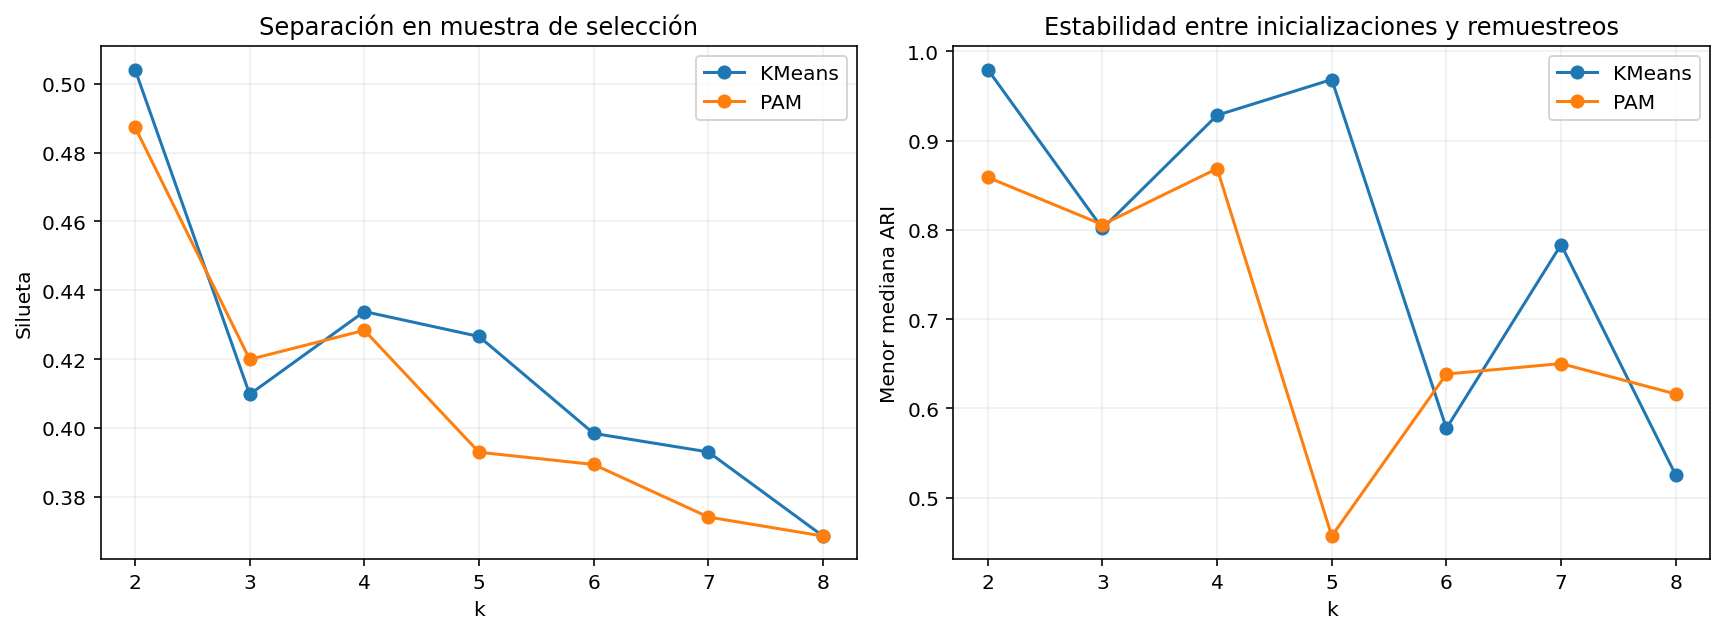

### Sensibilidad a transformaciones

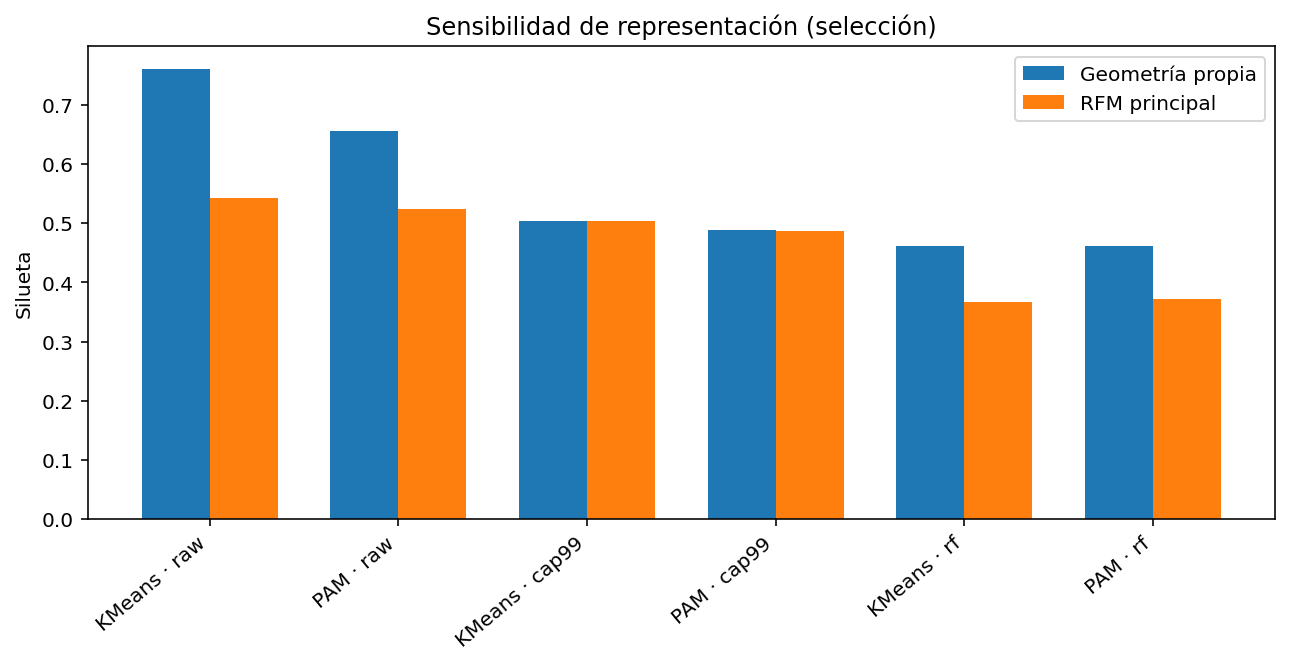

### Recencia por segmento

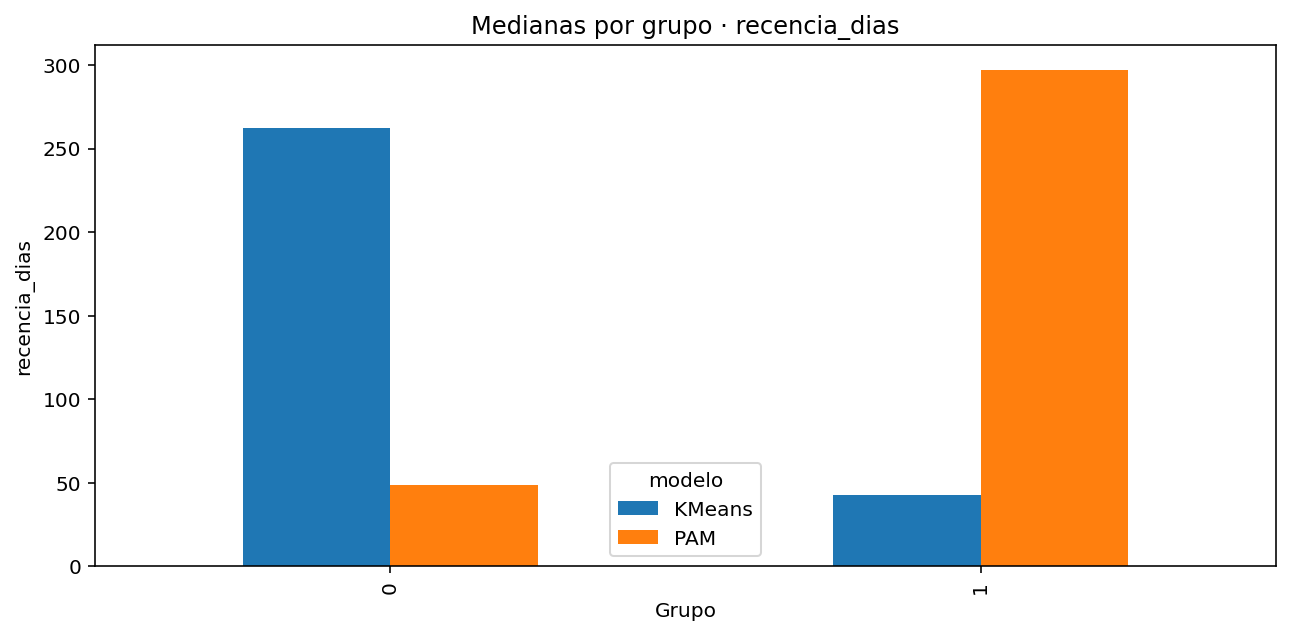

### Frecuencia por segmento

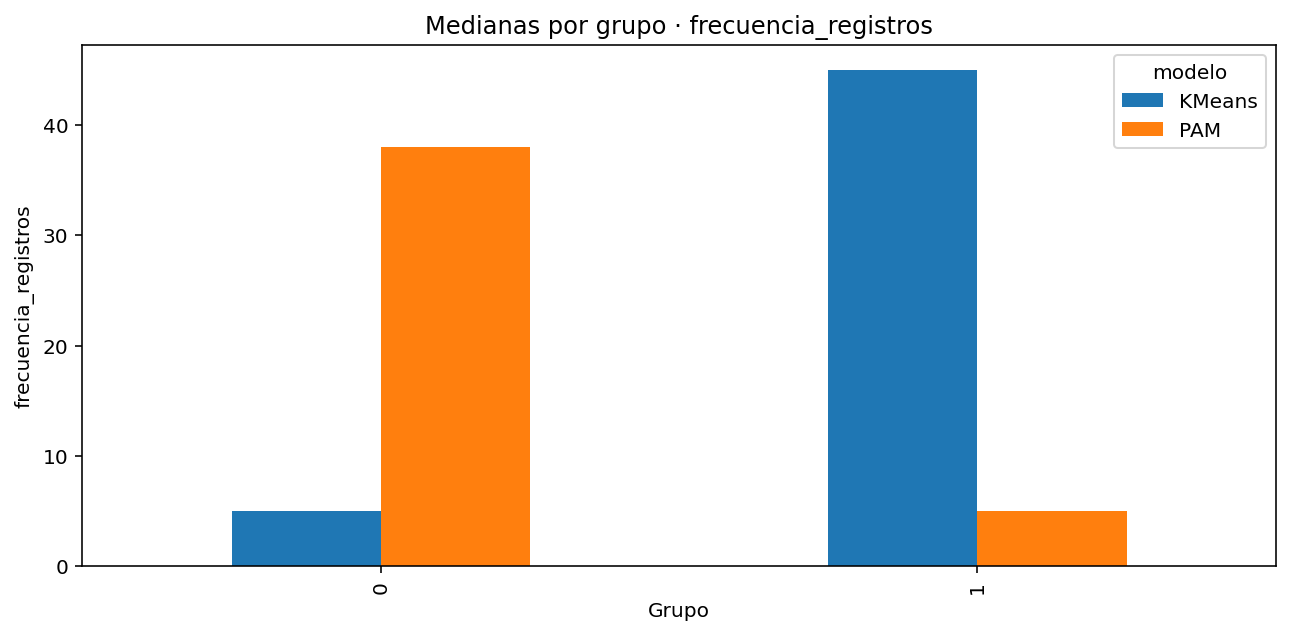

In [17]:
# Galería de resultados: se muestran LAS FIGURAS realmente generadas en la evaluación.
from IPython.display import display, Markdown, Image
from pathlib import Path
import pandas as pd
figuras=[('Silueta y estabilidad', 'md1_evaluacion_k_y_estabilidad.png'), ('Sensibilidad a transformaciones', 'md1_evaluacion_sensibilidad.png'), ('Recencia por segmento', 'md1_perfiles_recencia_dias.png'), ('Frecuencia por segmento', 'md1_perfiles_frecuencia_registros.png')]
tablas=[('Comparación k y estabilidad', 'md1_seleccion_k.csv'), ('Resultados de test', 'md1_evaluacion_final.csv'), ('Perfiles interpretables', 'md1_perfiles_finales.csv'), ('Sensibilidad', 'md1_sensibilidad.csv')]
for titulo, nombre in tablas:
    archivo=OUT/nombre
    if archivo.is_file() and archivo.stat().st_size>10:
        display(Markdown('### '+titulo))
        tabla=pd.read_csv(archivo)
        if len(tabla):display(tabla.head(18).round(4))
    else:display(Markdown(f'**Pendiente:** {titulo} (no se generó {nombre})'))
for titulo,nombre in figuras:
    archivo=OUT/nombre
    if archivo.is_file() and archivo.stat().st_size>100:
        display(Markdown('### '+titulo));display(Image(filename=str(archivo)))
    else: display(Markdown(f'**Figura pendiente:** {titulo}'))


## 9. Validación final y controles de generalización

Revisión de resultados retenidos, sensibilidad y estados P01–P04, sin utilizar test para reoptimizar hiperparámetros.


In [18]:
display(Markdown('**Selección:** '+str(json.loads((OUT/'md1_decision_final.json').read_text()).get('preferencia','PENDIENTE')) if (OUT/'md1_decision_final.json').exists() else '**Selección pendiente**'))

**Selección:** KMeans

## 10. Interpretación científica y limitaciones

Los grupos RFM describen patrones históricos; ni M ni la silueta prueban rentabilidad o causalidad.


## 11. Persistencia del modelo y prueba de recarga

Guardar artefactos privados **reutilizables**, probar recarga y distinguir resultados experimentales de refits de uso posterior. No publicar el ZIP privado en GitHub.


In [19]:
# Persistencia segura MD-1: centros numéricos y estado de transformación, sin pickle.
from pathlib import Path
import json, numpy as np
from IPython.display import display,Markdown
MD_MODELS=OUT/'modelos';MD_MODELS.mkdir(parents=True,exist_ok=True)
PERSISTENCIA={'objetivo':'MD1','estado':'INCOMPLETO','modelos':{},'alcance':'muestra_ajuste_4000'}
if K_CHOSEN is None or not all((m,K_CHOSEN) in MAIN for m in ('KMeans','PAM')):
    print('PERSISTENCIA INCOMPLETA: no hay modelos K-means/PAM válidos en memoria')
else:
    for tipo in ('KMeans','PAM'):
        modelo=MAIN[(tipo,K_CHOSEN)]['model']; state=modelo['state']
        file=MD_MODELS/f'{tipo.lower()}_k{K_CHOSEN}.npz'
        np.savez_compressed(file,centers=np.asarray(modelo['centers'],dtype='float64'),
            median=np.asarray(state['median'],dtype='float64'),scale=np.asarray(state['scale'],dtype='float64'),
            cap=np.asarray(state['cap'],dtype='float64') if state.get('cap') is not None else np.array([],dtype='float64'),
            medoid_rows=np.asarray(modelo.get('medoid_rows',[]),dtype='int64'))
        with np.load(file,allow_pickle=False) as saved:
            assert np.array_equal(saved['centers'],np.asarray(modelo['centers']))
            assert np.array_equal(saved['median'],np.asarray(state['median']))
            assert np.array_equal(saved['scale'],np.asarray(state['scale']))
            test_x=trans(test_ref,state)
            ref=np.argmin(pairwise_distances(test_x,modelo['centers']),axis=1)
            loaded=np.argmin(pairwise_distances(test_x,saved['centers']),axis=1)
            assert np.array_equal(ref,loaded)
        PERSISTENCIA['modelos'][tipo]={'archivo':file.name,'k':K_CHOSEN,'kind':state['kind'],
                   'features':['recencia_dias','frecuencia_registros','valor_agregado_price'],
                   'test_reproducible_2000':True,'tipo':'centros_y_transformacion'}
    PERSISTENCIA['estado']='PERSISTIDO_REUTILIZABLE'
(MD_MODELS/'estado_modelos.json').write_text(json.dumps(PERSISTENCIA,indent=2,ensure_ascii=False),encoding='utf-8')
display(Markdown('**Persistencia MD-1:** '+PERSISTENCIA['estado']))


**Persistencia MD-1:** PERSISTIDO_REUTILIZABLE

## 12. Auditoría y exportación de entregables

Primero se recalcula el inventario; luego se crean **dos ZIP separados** con manifiesto SHA-256 y comprobación de integridad. El notebook ejecutado se guarda por separado desde Kaggle.


In [20]:

CLAVES_MD1=['md1_piloto_pam.csv','md1_seleccion_k.csv','md1_ari_repeticiones.csv',
           'md1_sensibilidad.csv','md1_perfiles_finales.csv','md1_evaluacion_final.csv','md1_decision_final.json']
presentes={p:(OUT/p).exists() for p in CLAVES_MD1}
no_listos=[p for p,ok in presentes.items() if not ok]
save_json({'archivos':presentes,'completo':not no_listos,'faltantes':no_listos},'md1_auditoria_entregables.json')
print('MD-1:', 'salidas completas' if not no_listos else 'PENDIENTE: '+', '.join(no_listos))


Guardado: /kaggle/working/hm_modelamiento/md1/md1_auditoria_entregables.json
MD-1: salidas completas


In [21]:
# Exportación única: ZIP de evidencias público-revisable y ZIP de modelos PRIVADO.
# ZIP 1 excluye datos de clientes/Parquet, plantillas con descripciones y pesos binarios.
from pathlib import Path
from IPython.display import display,FileLink,Markdown
import hashlib,json,zipfile,datetime
OBJETIVO='md1'
ROOT=Path('/kaggle/working') if Path('/kaggle/working').is_dir() else OUT.parent.parent
ROOT.mkdir(parents=True,exist_ok=True)
MODEL_DIR=OUT/'modelos'
def sha_file(p):
    h=hashlib.sha256()
    with open(p,'rb') as f:
        for b in iter(lambda:f.read(4*2**20),b''):h.update(b)
    return h.hexdigest()
def empaquetar(files,zfile,root,privado):
    manifest={'objetivo':OBJETIVO,'privado':privado,'generado_utc':datetime.datetime.now(datetime.timezone.utc).isoformat(),
              'archivos':[]}
    with zipfile.ZipFile(zfile,'w',zipfile.ZIP_DEFLATED,compresslevel=3,allowZip64=True) as z:
        for j,p in enumerate(files,1):
            name=str(p.relative_to(root)).replace('\\','/')
            z.write(p,arcname=f'{OBJETIVO}/{name}')
            manifest['archivos'].append({'ruta':name,'tamano_bytes':p.stat().st_size,'sha256':sha_file(p)})
            if j%10==0 or j==len(files):print(f'[ZIP {"MODELOS" if privado else "EVIDENCIAS"}] {j}/{len(files)} archivos',flush=True)
        z.writestr(f'{OBJETIVO}/manifest_exportacion.json',json.dumps(manifest,ensure_ascii=False,indent=2))
    with zipfile.ZipFile(zfile) as check:
        assert check.testzip() is None
        assert f'{OBJETIVO}/manifest_exportacion.json' in check.namelist()
    return manifest
allowed={'.csv','.json','.jsonl','.png','.md','.svg','.txt'}
exclude_names={'referencia_seleccion.csv','referencia_test.csv','md4_consultas_holdout.csv',
               'md4_consultas_ajuste.csv','md2_popularidad_articulos_desarrollo.csv','md4_plantilla_pps_ciega.csv','md4_plantilla_pps_todos_escenarios.csv'}
evidencias=sorted(p for p in OUT.rglob('*') if p.is_file() and not p.is_relative_to(MODEL_DIR)
   and p.suffix.lower() in allowed and p.name not in exclude_names
   and not p.name.startswith('md4_pps_evaluaciones')
   and not any(part in {'cache_ajustes','incidencia','cache','temp','tmp'} for part in p.relative_to(OUT).parts))
modelos=sorted(p for p in MODEL_DIR.rglob('*') if p.is_file()) if MODEL_DIR.exists() else []
zip_e=ROOT/f'HM_{OBJETIVO.upper()}_Evidencias.zip'
zip_m=ROOT/f'HM_{OBJETIVO.upper()}_Modelos_PRIVADO.zip'
man_e=empaquetar(evidencias,zip_e,OUT,False)
man_m=empaquetar(modelos,zip_m,OUT,True)
assert zip_e.exists() and zip_m.exists() and len(man_e['archivos'])>0 and len(man_m['archivos'])>0
print('EVIDENCIAS:',zip_e,round(zip_e.stat().st_size/2**20,2),'MiB')
print('MODELOS PRIVADOS:',zip_m,round(zip_m.stat().st_size/2**20,2),'MiB')
display(Markdown('**Descarga 1 — Evidencias de modelado y evaluación**'))
display(FileLink(str(zip_e)))
display(Markdown('**Descarga 2 — Modelos reutilizables (privado: no publicar en GitHub)**'))
display(FileLink(str(zip_m)))


[ZIP EVIDENCIAS] 10/24 archivos
[ZIP EVIDENCIAS] 20/24 archivos
[ZIP EVIDENCIAS] 24/24 archivos
[ZIP MODELOS] 3/3 archivos
EVIDENCIAS: /kaggle/working/HM_MD1_Evidencias.zip 0.26 MiB
MODELOS PRIVADOS: /kaggle/working/HM_MD1_Modelos_PRIVADO.zip 0.0 MiB


**Descarga 1 — Evidencias de modelado y evaluación**

/kaggle/working/HM_MD1_Evidencias.zip

**Descarga 2 — Modelos reutilizables (privado: no publicar en GitHub)**

/kaggle/working/HM_MD1_Modelos_PRIVADO.zip

## 13. Conclusiones y estado de cierre

Las conclusiones siguientes se generan a partir de los archivos de evaluación y persistencia, no de una declaración estática.


In [22]:
# Cierre ejecutivo derivado de archivos realmente generados.
from IPython.display import display,Markdown
import json
estado_path=OUT/'md1_estado_semana12.json'
eval_state=json.loads(estado_path.read_text()) if estado_path.is_file() else {'estado':'SIN_EVALUACION'}
model_path=OUT/'modelos'/'estado_modelos.json'
mod_state=json.loads(model_path.read_text()) if model_path.is_file() else {'estado':'SIN_PERSISTENCIA'}
pend=[f"{i.get('prueba','?')}: {i.get('estado')}" for i in eval_state.get('pruebas',[])
      if i.get('estado') not in ('PASS','EVALUADO')]
texto=(f'### Resultado final — MD-1\n'
      f'- **Modelado y evaluación:** `{eval_state.get("estado","DESCONOCIDO")}`.\n'
      f'- **Persistencia reutilizable:** `{mod_state.get("estado","DESCONOCIDO")}`.\n'
      f'- **Pruebas con reservas:** {", ".join(pend) if pend else "sin pendientes reportados en el estado automatizado"}.\n'
      f'- **Entregables:** `HM_MD1_Evidencias.zip` y `HM_MD1_Modelos_PRIVADO.zip`.\n'
      '- **Alcance:** las conclusiones deben respetar los protocolos, muestras y particiones declaradas; no hay recalificación retrospectiva con test.\n')
display(Markdown(texto))


### Resultado final — MD-1
- **Modelado y evaluación:** `EVALUADO`.
- **Persistencia reutilizable:** `PERSISTIDO_REUTILIZABLE`.
- **Pruebas con reservas:** sin pendientes reportados en el estado automatizado.
- **Entregables:** `HM_MD1_Evidencias.zip` y `HM_MD1_Modelos_PRIVADO.zip`.
- **Alcance:** las conclusiones deben respetar los protocolos, muestras y particiones declaradas; no hay recalificación retrospectiva con test.
